# WFLW preparation notebook

This notebook processes the WFLW dataset into an images folder and a labels.csv file. The source of this dataset is: https://wywu.github.io/projects/LAB/WFLW.html

In [1]:
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt
os.chdir('..')

In [2]:
dataset_dir = os.path.join('data', 'datasets', 'landmark detection', 'WFLW')
os.path.exists(dataset_dir)

True

In [3]:
new_images_dir = os.path.join(dataset_dir, 'Images')
os.makedirs(new_images_dir, exist_ok = True)

In [4]:
test_annotations = os.path.join(dataset_dir, 'WFLW_annotations', 'list_98pt_rect_attr_train_test', 'list_98pt_rect_attr_test.txt')
train_annotations = os.path.join(dataset_dir, 'WFLW_annotations', 'list_98pt_rect_attr_train_test', 'list_98pt_rect_attr_train.txt')

os.path.exists(test_annotations), os.path.exists(train_annotations)

(True, True)

In [5]:
image_paths = []
landmarks = []
split = []

In [6]:
with open(train_annotations, 'r') as train_annotations_file:
    lines = train_annotations_file.readlines()
    for line in lines:
        output = line.split(' ')
        points = np.array(output[0 : 98*2], dtype = np.float32)
        name = output[-1]
        name = name.replace('\n', '')

        image_paths.append(name)
        landmarks.append(points)
        split.append('train')

In [7]:
with open(test_annotations, 'r') as test_annotations_file:
    lines = test_annotations_file.readlines()
    for line in lines:
        output = line.split(' ')
        points = np.array(output[0 : 98*2], dtype = np.float32)
        name = output[-1].strip()
        name = name.replace('\n', '')
        
        image_paths.append(name)
        landmarks.append(points)
        split.append('test')

In [8]:
# Maps the left-side indices to their exact right-side counterparts for WFLW (0-indexed)
WFLW_FLIP_INDICES = [
    # Face Contour (0-32)
    32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 17, 16, 
    15, 14, 13, 12, 11, 10, 9, 8, 7, 6, 5, 4, 3, 2, 1, 0, 
    
    # Eyebrows (33-50)
    46, 45, 44, 43, 42, 50, 49, 48, 47, 
    37, 36, 35, 34, 33, 41, 40, 39, 38, 
    
    # Nose (51-59) - Note: 51-54 and 57 map to themselves (center line)
    51, 52, 53, 54, 59, 58, 57, 56, 55, 
    
    # Eyes (60-75)
    72, 71, 70, 69, 68, 75, 74, 73, 
    64, 63, 62, 61, 60, 67, 66, 65, 
    
    # Outer Lips (76-87) - Note: 79 and 85 are centers
    82, 81, 80, 79, 78, 77, 76, 87, 86, 85, 84, 83, 
    
    # Inner Lips (88-95) - Note: 90 and 94 are centers
    92, 91, 90, 89, 88, 95, 94, 93, 
    
    # Pupils (96-97)
    97, 96
]

In [9]:
from utility_scripts.landmark_utilities import preprocess_face_image_and_landmarks
import cv2

image_size = 224

In [10]:
new_landmarks = []
image_names = []
new_split = []
for i in range(len(image_paths)):
    image_path = os.path.join(dataset_dir, 'WFLW_images', image_paths[i])
    image = cv2.imread(image_path)
    points = landmarks[i]
    points = points.reshape(98, 2)

    new_image, new_landmark_points = preprocess_face_image_and_landmarks(image = image, landmarks = points, padding = 1.5, target_size = image_size)

    image_name = f'{i}.jpg'
    cv2.imwrite(os.path.join(new_images_dir, image_name), new_image)
    new_landmarks.append(new_landmark_points)
    image_names.append(image_name)
    new_split.append(split[i])


    if split[i] == 'train':
        flipped_image = new_image[:, ::-1, :]
        flipped_landmarks = new_landmark_points.copy()
        flipped_landmarks[:, 0] = image_size - flipped_landmarks[:, 0]
        flipped_landmarks = flipped_landmarks[WFLW_FLIP_INDICES, :]

        flipped_image_name = f'{i}_flipped.jpg'
        cv2.imwrite(os.path.join(new_images_dir, flipped_image_name), flipped_image)
        new_landmarks.append(flipped_landmarks)
        image_names.append(flipped_image_name)
        new_split.append('train')


In [11]:
new_landmarks = np.array(new_landmarks)
new_landmarks.shape

(17500, 98, 2)

In [12]:
landmarks_dict = {}
for point in range(98):
    landmarks_dict[f'x{point}'] = (new_landmarks[:, point, 0])
    landmarks_dict[f'y{point}'] = (new_landmarks[:, point, 1])

In [13]:
labels_df = pd.DataFrame(
    data = {
        'filename' : image_names,
        **landmarks_dict,
        'split' : new_split,
    }
)

In [14]:
labels_df.to_csv(os.path.join(dataset_dir, 'labels.csv'), index = False)

In [15]:
labels_df

,filename,x0,y0,x1,y1,x2,y2,x3,y3,x4,...,y93,x94,y94,x95,y95,x96,y96,x97,y97,split
0,0.jpg,38.386549,60.171960,41.594710,68.333451,43.251034,76.923328,42.242521,85.603961,40.434547,...,136.663696,75.259080,138.542399,69.144099,138.238023,51.524591,69.006556,108.046504,66.987905,train
1,0_flipped.jpg,36.967926,48.988343,37.908812,61.066884,39.038287,73.129004,40.521583,85.152445,42.357278,...,138.238023,148.740920,138.542399,130.858130,136.663696,115.953496,66.987905,172.475409,69.006556,train
2,1.jpg,38.530680,60.716551,39.139133,71.537826,39.779414,82.357256,40.482094,93.172803,41.300930,...,135.715850,120.768320,137.235410,107.581688,138.597758,78.976789,63.856803,155.534422,60.838395,train
3,1_flipped.jpg,37.276039,49.789031,36.731078,60.527100,36.528680,71.276119,36.913023,82.020217,37.608648,...,138.597758,103.231680,137.235410,90.647539,135.715850,68.465578,60.838395,145.023211,63.856803,train
4,2.jpg,38.184480,52.647081,38.363687,64.116771,38.419158,75.587703,38.565576,87.057285,39.426297,...,139.934451,133.771894,141.904444,114.122653,139.829534,100.109981,64.726777,165.549303,63.547699,train
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17495,9995.jpg,38.949290,75.564045,39.542261,86.026887,40.310614,96.478095,41.430171,106.897004,43.071737,...,140.911971,126.873119,142.869306,114.265612,142.965825,85.905314,74.256406,151.842603,70.300154,test
17496,9996.jpg,47.038216,66.367253,46.851953,75.077279,45.351693,83.651823,42.868880,92.004492,40.458008,...,137.381771,88.057617,138.703776,79.548763,138.767057,62.600000,72.355534,133.955534,71.488867,test
17497,9997.jpg,39.187198,65.895723,39.298957,76.098374,39.587934,86.297291,40.228975,96.479636,41.404412,...,133.241168,123.064769,133.964054,109.969640,133.134162,83.764706,62.647059,150.235294,64.117647,test
17498,9998.jpg,39.824853,62.319165,40.337848,72.042746,40.634611,81.774962,40.680244,91.511976,40.898814,...,143.542095,104.130097,143.937020,90.072831,138.758198,77.783255,67.663399,141.450958,72.535923,test


# EDA

In [16]:
labels_df = pd.read_csv(os.path.join(dataset_dir, 'labels.csv'))

In [17]:
np.unique(labels_df['split'], return_counts = True)

(array(['test', 'train'], dtype=object), array([ 2500, 15000]))

In [18]:
def draw_landmarks(image, landmarks, draw_text = False):
    image = np.array(image)
    for i, (x, y) in enumerate(landmarks):
        image = cv2.circle(image, (int(x), int(y)), radius = 0, color = (0, 255, 0), thickness = 4)
        
        if draw_text:
            cv2.putText(image, str(i), (int(x)+2, int(y)+2), cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 0, 255), 2)
    return image


In [19]:
import cv2

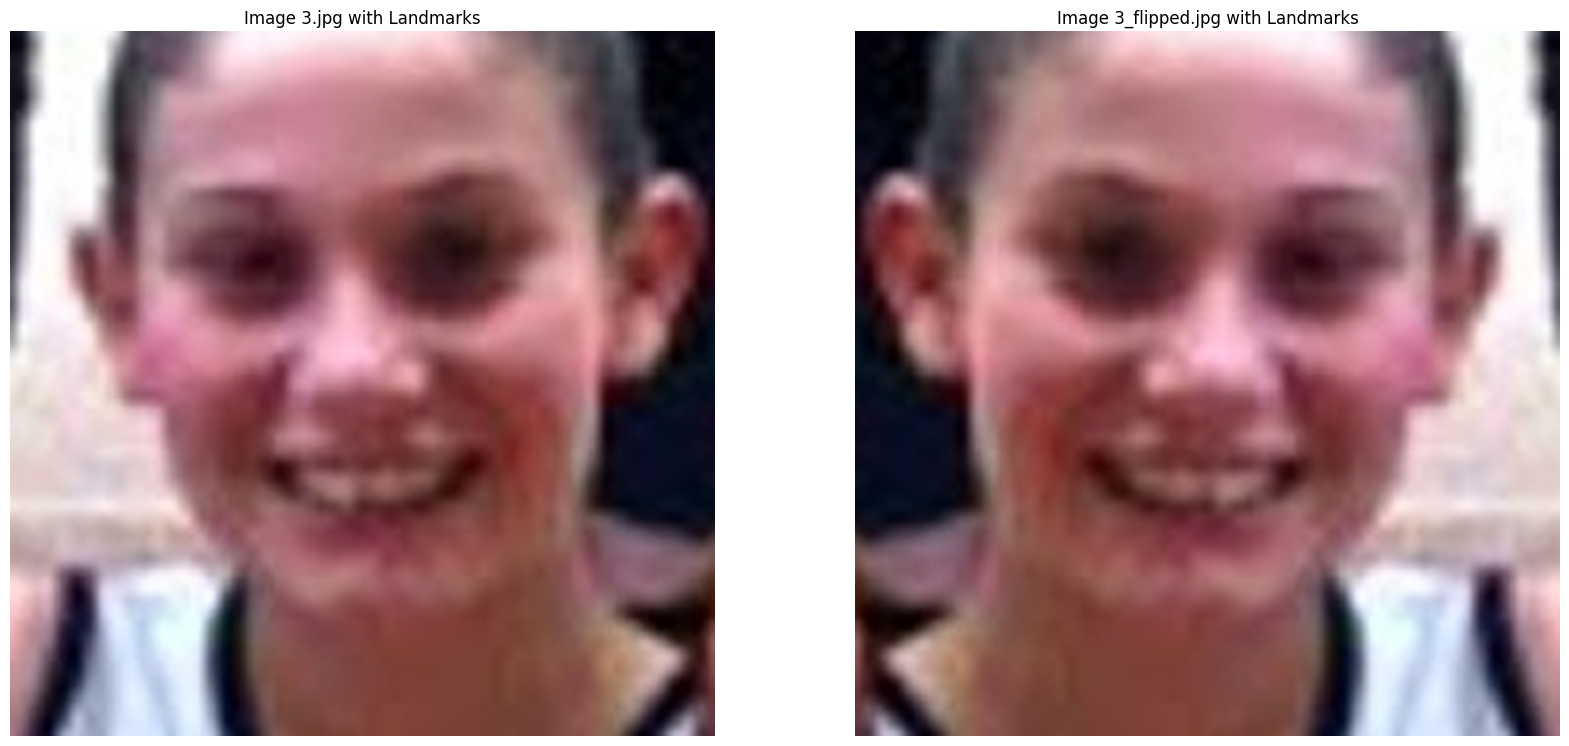

In [20]:
index1 = 6
index2 = 7
upsample_factor = 12
image = cv2.imread(os.path.join(new_images_dir, labels_df.loc[index1, 'filename']))
image2 = cv2.imread(os.path.join(new_images_dir, labels_df.loc[index2, 'filename']))
image = cv2.resize(image, (0, 0), fx = upsample_factor, fy = upsample_factor, interpolation = cv2.INTER_LANCZOS4)
image2 = cv2.resize(image2, (0, 0), fx = upsample_factor, fy = upsample_factor, interpolation = cv2.INTER_LANCZOS4)
landmarks = labels_df.loc[index1, [f'x{point}' for point in range(98)]].values, labels_df.loc[index1, [f'y{point}' for point in range(98)]].values
landmarks2 = labels_df.loc[index2, [f'x{point}' for point in range(98)]].values, labels_df.loc[index2, [f'y{point}' for point in range(98)]].values
landmarks = np.stack(landmarks, axis = 1)
landmarks2 = np.stack(landmarks2, axis = 1)
landmarks = landmarks * upsample_factor * image_size
landmarks2 = landmarks2 * upsample_factor * image_size
image_with_landmarks = draw_landmarks(image, landmarks, draw_text = True)
image2_with_landmarks = draw_landmarks(image2, landmarks2, draw_text = True)
plt.figure(figsize = (20, 10))
plt.subplot(1, 2, 1)
plt.title(f'Image {labels_df.loc[index1, "filename"]} with Landmarks')
plt.imshow(image_with_landmarks[:, :, ::-1])
plt.axis('off')
plt.subplot(1, 2, 2)
plt.title(f'Image {labels_df.loc[index2, "filename"]} with Landmarks')
plt.imshow(image2_with_landmarks[:, :, ::-1])
plt.axis('off')
plt.show()

In [21]:
labels_df.head()

,filename,x0,y0,x1,y1,x2,y2,x3,y3,x4,...,y93,x94,y94,x95,y95,x96,y96,x97,y97,split
0,0.jpg,38.386549,60.171960,41.594710,68.333451,43.251034,76.923328,42.242521,85.603961,40.434547,...,136.663696,75.259080,138.542399,69.144099,138.238023,51.524591,69.006556,108.046504,66.987905,train
1,0_flipped.jpg,36.967926,48.988343,37.908812,61.066884,39.038287,73.129004,40.521583,85.152445,42.357278,...,138.238023,148.740920,138.542399,130.858130,136.663696,115.953496,66.987905,172.475409,69.006556,train
2,1.jpg,38.530680,60.716551,39.139133,71.537826,39.779414,82.357256,40.482094,93.172803,41.300930,...,135.715850,120.768320,137.235410,107.581688,138.597758,78.976789,63.856803,155.534422,60.838395,train
3,1_flipped.jpg,37.276039,49.789031,36.731078,60.527100,36.528680,71.276119,36.913023,82.020217,37.608648,...,138.597758,103.231680,137.235410,90.647539,135.715850,68.465578,60.838395,145.023211,63.856803,train
4,2.jpg,38.184480,52.647081,38.363687,64.116771,38.419158,75.587703,38.565576,87.057285,39.426297,...,139.934451,133.771894,141.904444,114.122653,139.829534,100.109981,64.726777,165.549303,63.547699,train


/tmp/ipykernel_98562/435584621.py:11: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  x, y = landmarks[2*i], landmarks[2*i+1]


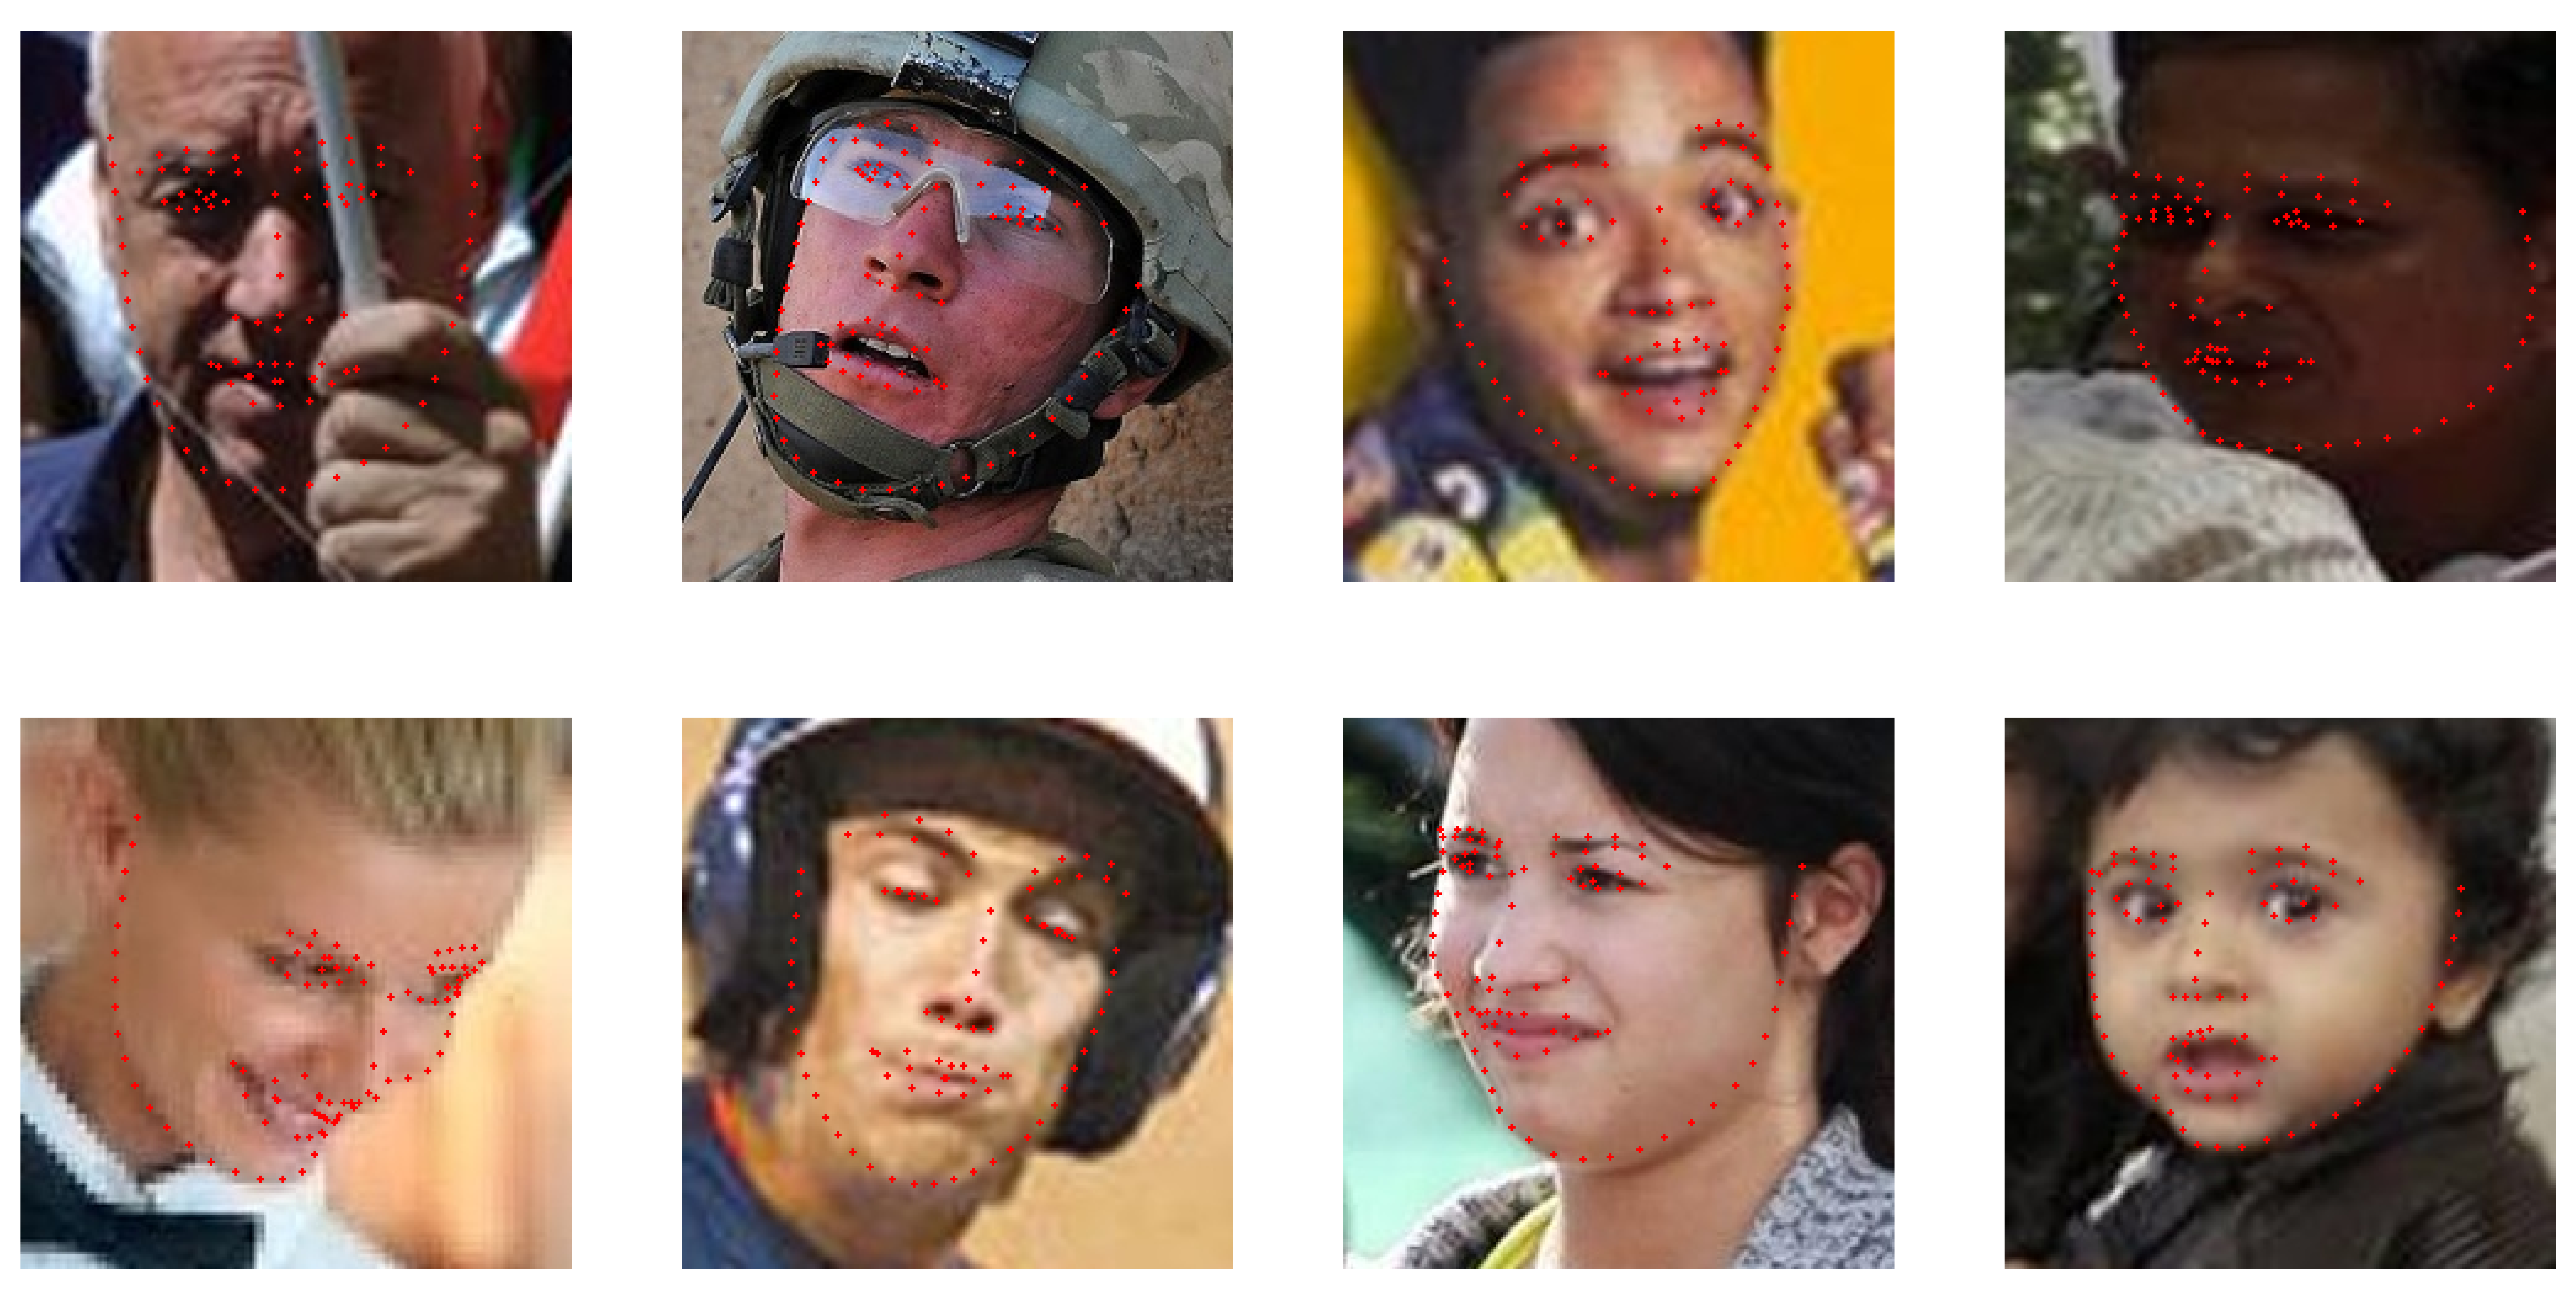

In [ ]:
plt.figure(figsize = (16, 8), dpi = 600)
plt.axis('off')
for image_index in range(8):
    index = np.random.randint(low = 0, high = len(labels_df))
    image_name = labels_df['filename'].iloc[index]
    image = cv2.imread(os.path.join(dataset_dir, 'Images', image_name))

    landmarks = labels_df[labels_df.columns[1:-1]].iloc[index]

    for i in range(len(landmarks) // 2):
        x, y = landmarks[2*i], landmarks[2*i+1]
        image = cv2.circle(image, center = (int(x), int(y)), radius = 0, color = (0, 0, 255), thickness = 2)

    plt.subplot(2, 4, image_index + 1)
    plt.imshow(image[:, :, ::-1])
    plt.axis('off')

plt.savefig(os.path.join('data', 'figures', 'Landmark detection', 'WFLW', 'Sample images from WFLW'))
plt.show()
    
    